# Real Data: Hippocampal Spatial Coding on a Bandit Task

This notebook demonstrates neurospatial analysis with **real neural recording data**
from rat hippocampus during a spatial bandit task.

**Dataset**: J16 session from July 10, 2021
- 203 hippocampal units
- 709,321 position samples at 500 Hz (~24 minutes)
- Maze with 3 reward patches (bandit task)

The first run downloads the 75 MB, CC BY 4.0 archive from
[Zenodo, version 1.0](https://doi.org/10.5281/zenodo.23020757).
The helper verifies its SHA-256 and reuses the local file on later runs.
Unit numbers below are export row indices; the archive does not include
original unit identities or curation labels. No database access is needed.

**Estimated time**: 30-40 minutes

**Prerequisites**: [05: track linearization](05_track_linearization.ipynb),
[11: place-field analysis](11_place_field_analysis.ipynb),
[13: trajectory analysis](13_trajectory_analysis.ipynb).

Run this notebook from a checkout of the repository: it uses the helper in
`data/` and the shared example styling. From the repository root, launch
`uv run --extra notebooks jupyter lab examples/`, then open this notebook.

## Learning Objectives

By the end of this notebook, you will be able to:

- Load already processed tracking and spike data, and check their time coverage
- Create a 1D linearized environment from a track graph
- Estimate spatial firing-rate maps from hippocampal spikes
- Analyze spatial coding with Skaggs information and sparsity
- Visualize place fields in both 2D and linearized 1D coordinates
- Distinguish spatial geometry, observed coverage and evidence of cell selectivity

Maps here pool the recording across travel directions and speeds, including
pauses at wells. Linearization supplies spatial coordinates; analyzing
direction or task history requires explicit labels, as in the follow-up notebooks.

In [1]:
# Import the data loading function
import importlib.util
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from neurospatial import Environment
from neurospatial.animation import HeadDirectionOverlay, PositionOverlay
from neurospatial.encoding import (
    compute_spatial_rates,
    detect_place_fields,
    field_size,
    rate_map_centroid,
)


def _find_project_root(start: Path) -> Path:
    """Find the project root containing the real-data helper."""
    for path in (start, *start.parents):
        if (path / "data" / "load_bandit_data.py").exists():
            return path
    raise FileNotFoundError(f"Could not find data/load_bandit_data.py from {start}")


# Determine base path (works in both scripts and notebooks)
try:
    # When running as a script
    _start_path = Path(__file__).resolve().parent
except NameError:
    # When running in Jupyter notebook
    _start_path = Path.cwd().resolve()
_base_path = _find_project_root(_start_path)

_data_dir = _base_path / "data"
_loader_path = _data_dir / "load_bandit_data.py"
_loader_spec = importlib.util.spec_from_file_location("load_bandit_data", _loader_path)
if _loader_spec is None or _loader_spec.loader is None:
    raise ImportError(f"Could not load bandit data helper from {_loader_path}")
_loader_module = importlib.util.module_from_spec(_loader_spec)
_loader_spec.loader.exec_module(_loader_module)
fetch_bandit_data = _loader_module.fetch_bandit_data
load_neural_recording_from_files = _loader_module.load_neural_recording_from_files

# Shared styling (Okabe-Ito palette, consistent figure / font sizes)
import sys

_here = (
    str(Path(__file__).resolve().parent) if "__file__" in globals() else str(Path.cwd())
)
if _here not in sys.path:
    sys.path.insert(0, _here)
from _style import apply_style

apply_style(figsize=(14, 10), font_size=12)

## Part 1: Load the Neural Recording Data

We load pre-processed data from a hippocampal recording session:
- Position tracking (head position, velocity, linear position)
- Spike times for 203 hippocampal units
- Track graph defining the maze structure

LED tracking has already been smoothed, upsampled to 500 Hz and linearized.
This notebook does not reconstruct those preprocessing steps. Spike times and
tracking share a clock, and positions are in centimeters. To download ahead
of time from the repository root, run `uv run python data/load_bandit_data.py`.

In [2]:
# Load the dataset
data_path = _base_path / "data"
data_file = fetch_bandit_data(data_path)
print(f"Verified dataset: {data_file.name}")
data = load_neural_recording_from_files(data_path, "j1620210710_02_r1")

# Extract components
position_info = data["position_info"].copy()
# Subtract the SAME origin from tracking and spikes, preserving their alignment.
time_origin = float(position_info.index[0])
position_info.index = position_info.index - time_origin
spike_times_all = [spikes - time_origin for spikes in data["spike_times"]]
track_graph = data["track_graph"]
linear_edge_order = data["linear_edge_order"]
linear_edge_spacing = data["linear_edge_spacing"]

# Get basic info
n_units = len(spike_times_all)
n_samples = len(position_info)
duration = position_info.index[-1] - position_info.index[0]
sample_rate = 1.0 / np.median(np.diff(position_info.index.to_numpy()))
max_gap = 0.5  # seconds; use the same recording-gap rule throughout the analysis

print("=" * 60)
print("J16 BANDIT TASK - NEURAL RECORDING DATA")
print("=" * 60)
print(f"\nRecording duration: {duration:.1f} seconds ({duration / 60:.1f} minutes)")
print(f"Position samples: {n_samples:,} at {sample_rate:.0f} Hz")
print(f"Hippocampal units: {n_units}")
print(f"Total spikes: {sum(len(s) for s in spike_times_all):,}")
print(f"Empty spike trains in this epoch: {sum(len(s) == 0 for s in spike_times_all)}")
print(f"Tracking gaps > {max_gap} s: {np.sum(np.diff(position_info.index) > max_gap)}")

Verified dataset: j1620210710_02_r1_figure04_inputs.npz
J16 BANDIT TASK - NEURAL RECORDING DATA

Recording duration: 1418.6 seconds (23.6 minutes)
Position samples: 709,321 at 500 Hz
Hippocampal units: 203
Total spikes: 870,018
Empty spike trains in this epoch: 21
Tracking gaps > 0.5 s: 0


### Examine Position Data

The position data includes 2D coordinates and pre-computed linear position:

In [3]:
print("\nPosition data columns:")
for col in position_info.columns:
    print(f"  - {col}")

print("\n2D position range:")
print(
    f"  X: [{position_info['head_position_x'].min():.1f}, {position_info['head_position_x'].max():.1f}] cm"
)
print(
    f"  Y: [{position_info['head_position_y'].min():.1f}, {position_info['head_position_y'].max():.1f}] cm"
)

print(
    f"\nLinear position range: [{position_info['linear_position'].min():.1f}, {position_info['linear_position'].max():.1f}] cm"
)
print(f"Track segments: {sorted(position_info['track_segment_id'].unique())}")
print(
    f"Reward patches: {sorted(position_info['patch_id'].dropna().unique().astype(int))}"
)


Position data columns:
  - head_position_x
  - head_position_y
  - head_orientation
  - head_velocity_x
  - head_velocity_y
  - head_speed
  - linear_position
  - track_segment_id
  - projected_x_position
  - projected_y_position
  - patch_id

2D position range:
  X: [30.1, 232.7] cm
  Y: [33.3, 222.9] cm

Linear position range: [0.3, 608.5] cm
Track segments: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
Reward patches: [np.int64(1), np.int64(2), np.int64(3)]


### Examine Track Graph

The maze is defined by a graph with 10 nodes (including arm endpoints,
junction nodes, and center):

In [4]:
print("\nTrack graph structure:")
print(f"  Nodes: {track_graph.number_of_nodes()}")
print(f"  Edges: {track_graph.number_of_edges()}")

print("\nNode positions:")
for node in sorted(track_graph.nodes()):
    pos = track_graph.nodes[node]["pos"]
    print(f"  Node {node}: ({pos[0]:.1f}, {pos[1]:.1f}) cm")

print("\nEdge order for linearization:")
for i, edge in enumerate(linear_edge_order):
    print(f"  {i}: {edge}")


Track graph structure:
  Nodes: 10
  Edges: 9

Node positions:
  Node 0: (179.5, 45.1) cm
  Node 1: (225.7, 123.3) cm
  Node 2: (184.2, 205.0) cm
  Node 3: (88.9, 209.7) cm
  Node 4: (37.9, 128.5) cm
  Node 5: (88.2, 45.1) cm
  Node 6: (179.6, 99.7) cm
  Node 7: (135.4, 180.5) cm
  Node 8: (87.5, 99.6) cm
  Node 9: (135.6, 127.3) cm

Edge order for linearization:
  0: (9, 6)
  1: (6, 0)
  2: (6, 1)
  3: (9, 7)
  4: (7, 2)
  5: (7, 3)
  6: (9, 8)
  7: (8, 4)
  8: (8, 5)


## Part 2: Visualize the Maze and Trajectory

Let's visualize the track structure and the animal's trajectory:

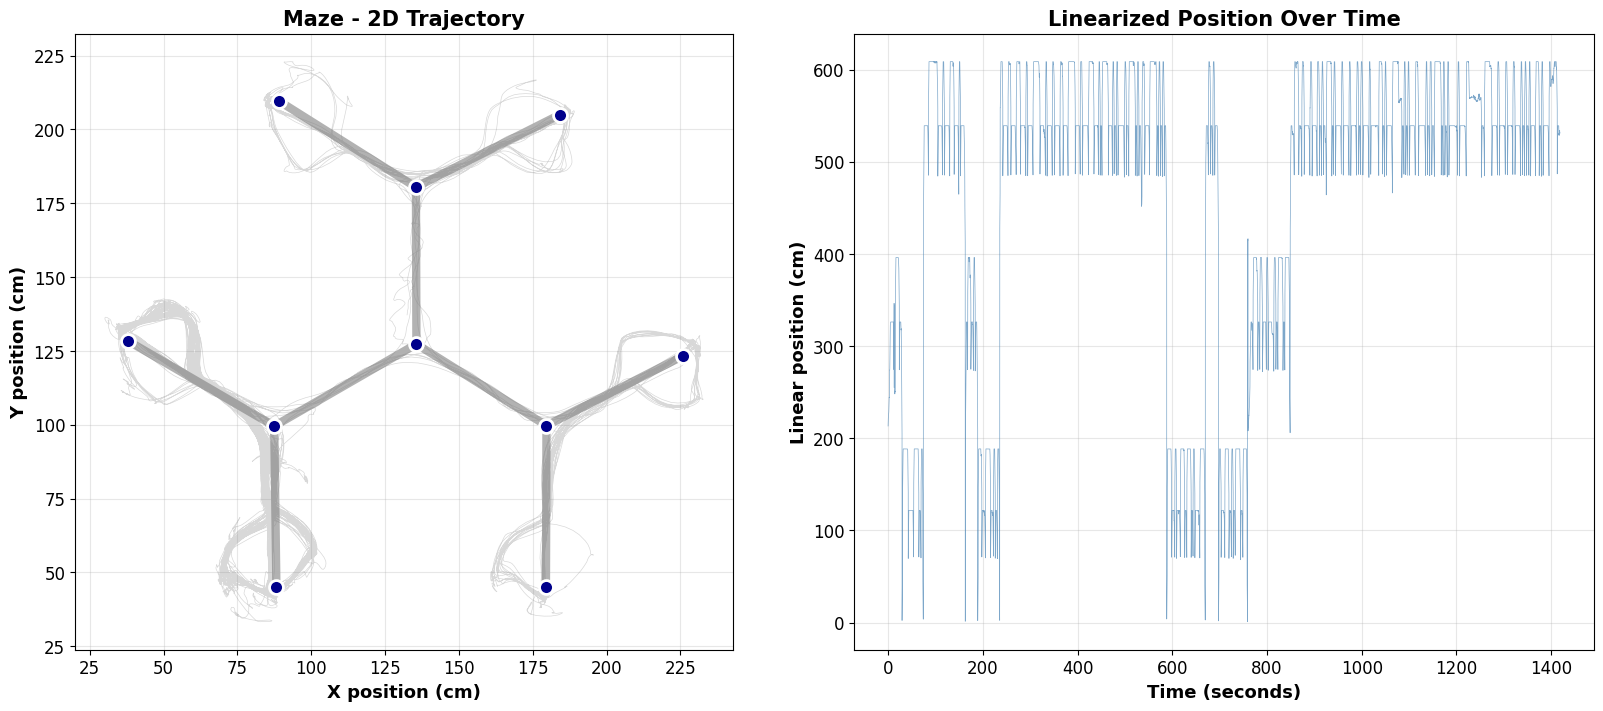


Trajectory covers the full maze with repeated visits to all arms


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)

# Left: 2D trajectory
ax = axes[0]
positions_2d = position_info[["head_position_x", "head_position_y"]].values

# Subsample for visualization
subsample = 20
ax.plot(
    positions_2d[::subsample, 0],
    positions_2d[::subsample, 1],
    "gray",
    alpha=0.3,
    linewidth=0.5,
    label="Trajectory",
)

# Draw track graph edges
for u, v in track_graph.edges():
    pos_u = np.array(track_graph.nodes[u]["pos"])
    pos_v = np.array(track_graph.nodes[v]["pos"])
    ax.plot(
        [pos_u[0], pos_v[0]],
        [pos_u[1], pos_v[1]],
        "k-",
        linewidth=6,
        alpha=0.3,
        zorder=1,
    )

# Mark nodes
for node in track_graph.nodes():
    pos = track_graph.nodes[node]["pos"]
    ax.scatter(
        pos[0], pos[1], s=100, c="darkblue", edgecolor="white", linewidth=2, zorder=10
    )
    ax.annotate(
        str(node),
        (pos[0], pos[1]),
        fontsize=10,
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
    )

ax.set_xlabel("X position (cm)", fontsize=13, fontweight="bold")
ax.set_ylabel("Y position (cm)", fontsize=13, fontweight="bold")
ax.set_title("Maze - 2D Trajectory", fontsize=15, fontweight="bold")
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)

# Right: Linear position over time
ax = axes[1]
times = position_info.index.values
linear_pos = position_info["linear_position"].values

# Use relative time (seconds from start)
times_relative = times - times[0]

ax.plot(
    times_relative[::subsample],
    linear_pos[::subsample],
    "steelblue",
    linewidth=0.5,
    alpha=0.7,
)
ax.set_xlabel("Time (seconds)", fontsize=13, fontweight="bold")
ax.set_ylabel("Linear position (cm)", fontsize=13, fontweight="bold")
ax.set_title("Linearized Position Over Time", fontsize=15, fontweight="bold")
ax.grid(True, alpha=0.3)

plt.show()

print("\nTrajectory covers the full maze with repeated visits to all arms")

## Part 3: Create Linearized Environment

We use `Environment.from_graph()` to preserve the maze centerline's connectivity.
Its bins have 2D locations and a separate linearized coordinate. The edge order
and inserted gaps define the display coordinate; they do not encode running
direction. We compare graph-based neural maps with the 2D maps in Part 6a.

In [6]:
# Create 1D linearized environment from track graph
env_1d = Environment.from_graph(
    graph=track_graph,
    edge_order=linear_edge_order,
    edge_spacing=linear_edge_spacing,
    bin_size=2.0,  # 2 cm bins for fine-grained analysis
    name="Maze_1D",
)
env_1d.units = "cm"

print("1D Linearized Environment Created!")
print(f"  Is 1D: {env_1d.is_linearized_track}")
print(f"  Number of bins: {env_1d.n_bins}")
linear_bin_centers = env_1d.to_linear(env_1d.bin_centers)
print(
    f"  Linear bin-center range: [{linear_bin_centers.min():.1f}, "
    f"{linear_bin_centers.max():.1f}] cm"
)

1D Linearized Environment Created!
  Is 1D: True
  Number of bins: 248
  Linear bin-center range: [1.0, 607.5] cm


A 2D grid gives a familiar overhead view. Its active bins come from visited
positions. This is a sampled approximation to the maze footprint, rather than
a surveyed wall model: its smoothing follows grid connectivity. The track
graph provides the known centerline topology for the comparison below.

In [7]:
# Create 2D environment from position samples
env_2d = Environment.from_samples(
    positions_2d,
    bin_size=4.0,  # Slightly coarser for 2D to ensure good occupancy
    name="Maze_2D",
)
env_2d.units = "cm"

print("\n2D Environment Created!")
print(f"  Is 1D: {env_2d.is_linearized_track}")
print(f"  Number of bins: {env_2d.n_bins}")
print(f"  Dimensions: {env_2d.n_dims}D")


2D Environment Created!
  Is 1D: False
  Number of bins: 557
  Dimensions: 2D


## Part 4: Examine Spike Data and Select Active Units

We retain units with at least 50 spikes for an exploratory population summary.
This count threshold does not establish isolation quality or place-cell identity.

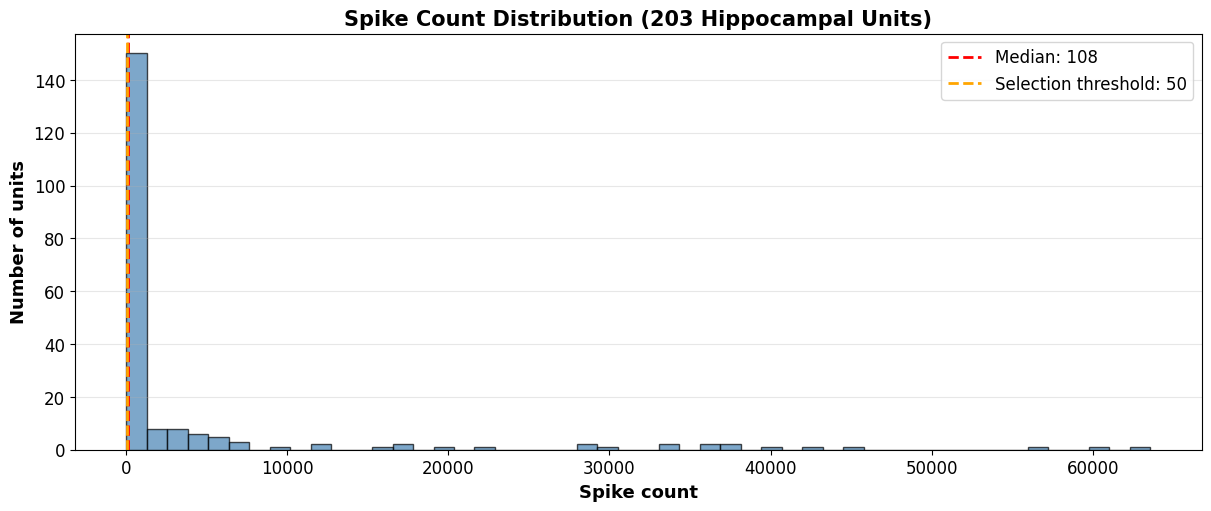


Units with >= 50 spikes: 108 / 203


In [8]:
# Count spikes for each unit
spike_counts = [len(s) for s in spike_times_all]

fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)

ax.hist(spike_counts, bins=50, color="steelblue", edgecolor="black", alpha=0.7)
ax.axvline(
    np.median(spike_counts),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Median: {np.median(spike_counts):.0f}",
)
ax.axvline(
    50, color="orange", linestyle="--", linewidth=2, label="Selection threshold: 50"
)
ax.set_xlabel("Spike count", fontsize=13, fontweight="bold")
ax.set_ylabel("Number of units", fontsize=13, fontweight="bold")
ax.set_title(
    "Spike Count Distribution (203 Hippocampal Units)", fontsize=15, fontweight="bold"
)
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3, axis="y")

plt.show()

# Select units with sufficient spikes for analysis
min_spikes = 50
active_units = [i for i, count in enumerate(spike_counts) if count >= min_spikes]
print(f"\nUnits with >= {min_spikes} spikes: {len(active_units)} / {n_units}")

## Part 5: Estimate Spatial Rate Maps

We estimate rate maps for the retained population and show six units selected
by spike count alone. They include broad and spatially selective activity;
they have not been classified as place cells.
Mean firing rates below use exported spike count divided by epoch duration.
Information and sparsity describe the observed spatial map under its support mask.

In [9]:
# Prepare trajectory data
times_array = position_info.index.values
positions_array = positions_2d

# Select examples deterministically by spike count, without tuning on a map score.
example_units = [i for i in active_units if 3000 <= spike_counts[i] <= 20000][:6]
print(f"Analyzing {len(example_units)} example units:")
for _i, unit_idx in enumerate(example_units):
    print(
        f"  Unit {unit_idx}: {spike_counts[unit_idx]:,} spikes ({spike_counts[unit_idx] / duration:.1f} Hz mean rate)"
    )

Analyzing 6 example units:
  Unit 0: 4,732 spikes (3.3 Hz mean rate)
  Unit 9: 11,792 spikes (8.3 Hz mean rate)
  Unit 10: 15,844 spikes (11.2 Hz mean rate)
  Unit 14: 6,774 spikes (4.8 Hz mean rate)
  Unit 15: 9,216 spikes (6.5 Hz mean rate)
  Unit 25: 5,448 spikes (3.8 Hz mean rate)


### Estimate Population Maps

The 8 cm smoothing bandwidth and 0.5 s minimum occupancy are illustrative
analysis choices. The threshold uses raw time per bin; it can mask briefly
visited corridors and split supported space into separate patches. Inspect
that mask below before interpreting a rate map or counting candidate fields.
We include stationary periods and assume spikes were recorded throughout
the tracked epoch, because this export has no separate acquisition intervals.

In [10]:
# Compute the population once, sharing occupancy and smoothing across units.
# Unit labels are the export row indices selected above.
bandwidth_cm = 8.0
min_occupancy_s = 0.5
population_rates = compute_spatial_rates(
    env_2d,
    [spike_times_all[unit_idx] for unit_idx in active_units],
    times_array,
    positions_array,
    unit_ids=active_units,
    method="diffusion_kde",
    bandwidth=bandwidth_cm,
    min_occupancy=min_occupancy_s,
    max_gap=max_gap,
)
place_fields = {}
spatial_metrics = {}

for unit_idx in example_units:
    spikes = spike_times_all[unit_idx]
    result = population_rates.sel(unit_id=unit_idx)
    firing_rate = result.firing_rate

    place_fields[unit_idx] = firing_rate

    # Skaggs spatial information (bits/spike)
    info = result.spatial_information()

    # Sparsity
    sparse = result.sparsity()

    # Mean firing rate
    mean_rate = len(spikes) / duration

    # Peak firing rate
    peak_rate = np.nanmax(firing_rate)

    spatial_metrics[unit_idx] = {
        "spatial_info": info,
        "sparsity": sparse,
        "mean_rate": mean_rate,
        "peak_rate": peak_rate,
    }

print("\nSpatial rate maps computed for the retained population")


Spatial rate maps computed for the retained population


### Check occupancy and observed support

Occupancy is time observed in each bin. Gray rate-map bins are unsupported
observations under these settings; they are not evidence of zero firing.
The support panel shows which locations contribute to interpretation.

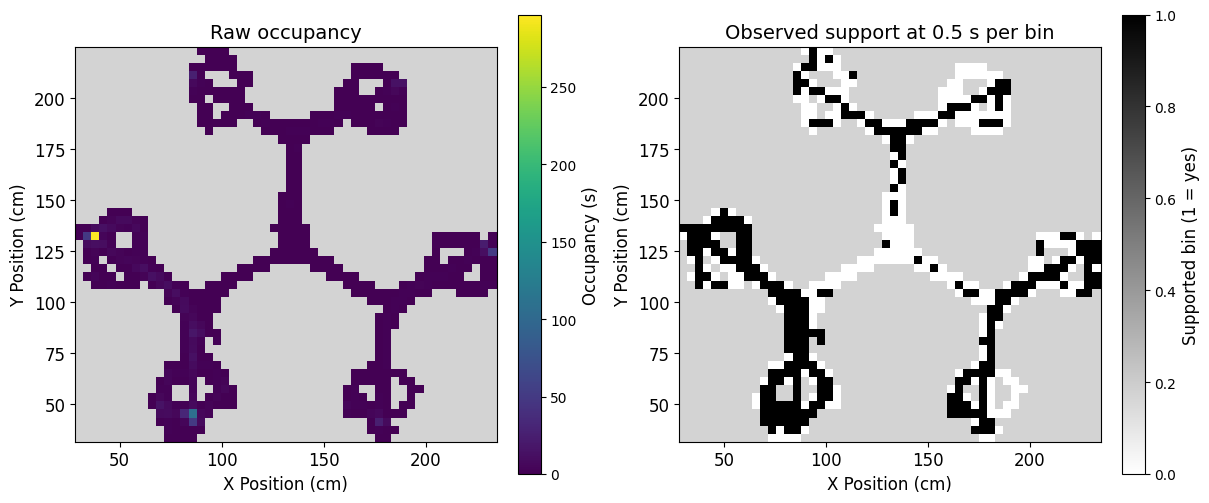

Observed tracking time: 1418.64 s
Supported bins: 275 / 557


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
env_2d.plot_field(
    population_rates.occupancy,
    ax=axes[0],
    cmap="viridis",
    vmin=0,
    colorbar_label="Occupancy (s)",
)
axes[0].set_title("Raw occupancy")
env_2d.plot_field(
    population_rates.spatial_support.astype(float),
    ax=axes[1],
    cmap="gray_r",
    vmin=0,
    vmax=1,
    colorbar_label="Supported bin (1 = yes)",
)
axes[1].set_title(f"Observed support at {min_occupancy_s:g} s per bin")
plt.show()
print(f"Observed tracking time: {population_rates.occupancy.sum():.2f} s")
print(f"Supported bins: {population_rates.spatial_support.sum()} / {env_2d.n_bins}")

### Analyze Spatial Metrics

In [12]:
print("\n" + "=" * 70)
print("SPATIAL CODING METRICS")
print("=" * 70)
print(
    f"{'Unit':<8} {'Spikes':<10} {'Mean Rate':<12} {'Peak Rate':<12} {'Skaggs Info':<14} {'Sparsity':<10}"
)
print("-" * 70)

for unit_idx in example_units:
    m = spatial_metrics[unit_idx]
    print(
        f"{unit_idx:<8} {spike_counts[unit_idx]:<10} {m['mean_rate']:<12.2f} {m['peak_rate']:<12.2f} {m['spatial_info']:<14.3f} {m['sparsity']:<10.3f}"
    )

print("-" * 70)
print("\nInterpretation:")
print("  Higher information indicates greater descriptive spatial selectivity.")
print("  Lower sparsity indicates activity concentrated in fewer locations.")
print("  These metrics and detected fields do not establish place-cell significance.")


SPATIAL CODING METRICS
Unit     Spikes     Mean Rate    Peak Rate    Skaggs Info    Sparsity  
----------------------------------------------------------------------
0        4732       3.34         20.99        1.412          0.253     
9        11792      8.31         27.32        0.129          0.845     
10       15844      11.17        20.00        0.088          0.884     
14       6774       4.77         7.34         0.027          0.961     
15       9216       6.50         14.04        0.055          0.924     
25       5448       3.84         24.20        1.202          0.393     
----------------------------------------------------------------------

Interpretation:
  Higher information indicates greater descriptive spatial selectivity.
  Lower sparsity indicates activity concentrated in fewer locations.
  These metrics and detected fields do not establish place-cell significance.


## Part 6: Visualize Spatial Rate Maps

Color scales start at zero, with a separate maximum for each unit. Compare
the labeled rates as well as spatial patterns: a broad map can have a visible
gradient without being strongly selective. Gray bins follow the support mask.

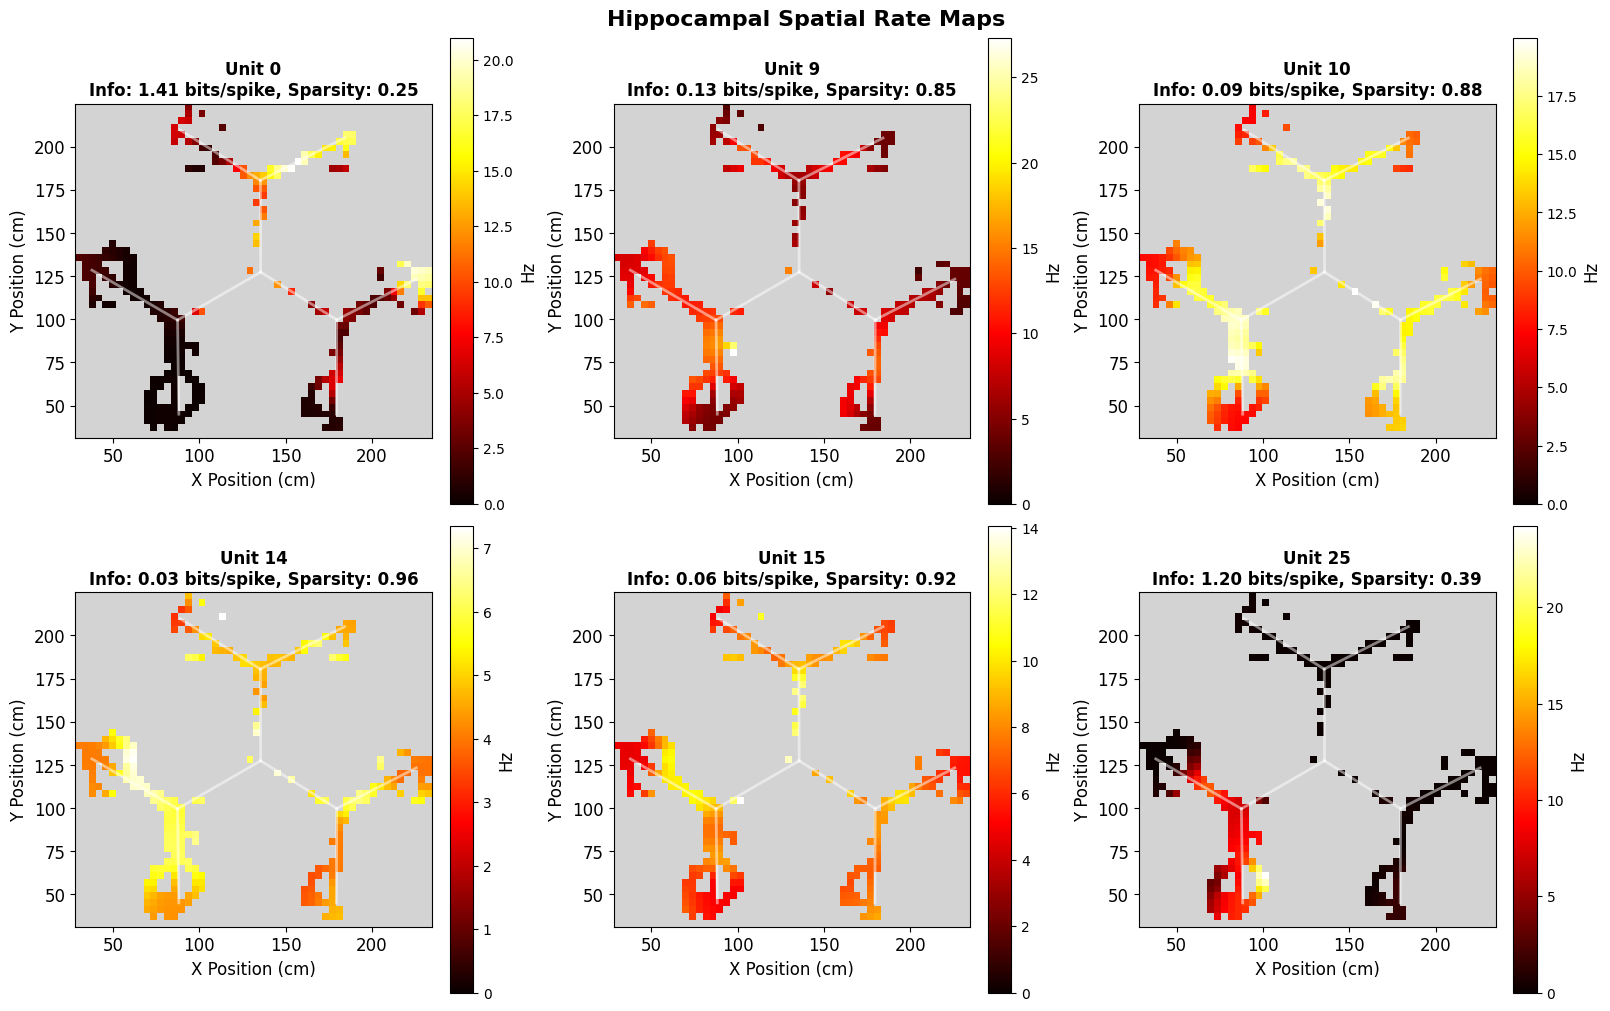

In [13]:
n_cols = 3
n_rows = 2
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 10), constrained_layout=True)
axes = axes.flatten()

for i, unit_idx in enumerate(example_units):
    ax = axes[i]

    # Plot place field
    env_2d.plot_field(
        place_fields[unit_idx],
        ax=ax,
        cmap="hot",
        vmin=0,
        colorbar_label="Hz",
    )

    # Add track graph overlay
    for u, v in track_graph.edges():
        pos_u = np.array(track_graph.nodes[u]["pos"])
        pos_v = np.array(track_graph.nodes[v]["pos"])
        ax.plot(
            [pos_u[0], pos_v[0]],
            [pos_u[1], pos_v[1]],
            "w-",
            linewidth=2,
            alpha=0.5,
        )

    m = spatial_metrics[unit_idx]
    ax.set_title(
        f"Unit {unit_idx}\nInfo: {m['spatial_info']:.2f} bits/spike, Sparsity: {m['sparsity']:.2f}",
        fontsize=12,
        fontweight="bold",
    )
    ax.set_aspect("equal")

plt.suptitle("Hippocampal Spatial Rate Maps", fontsize=16, fontweight="bold")
plt.show()

## Part 6a: Compare Maps Along the Track Graph

Recompute the same six units using the graph environment, the same 8 cm
bandwidth and 0.5 s occupancy threshold. Graph smoothing follows connected
track segments. The grid and graph divide space differently, so their
occupancy and rate estimates need not agree bin by bin.

Each line below uses physical linearized coordinates. Blank intervals mark
inserted edge-display gaps or unsupported bins. These coordinates describe
track geometry and pool both travel directions.

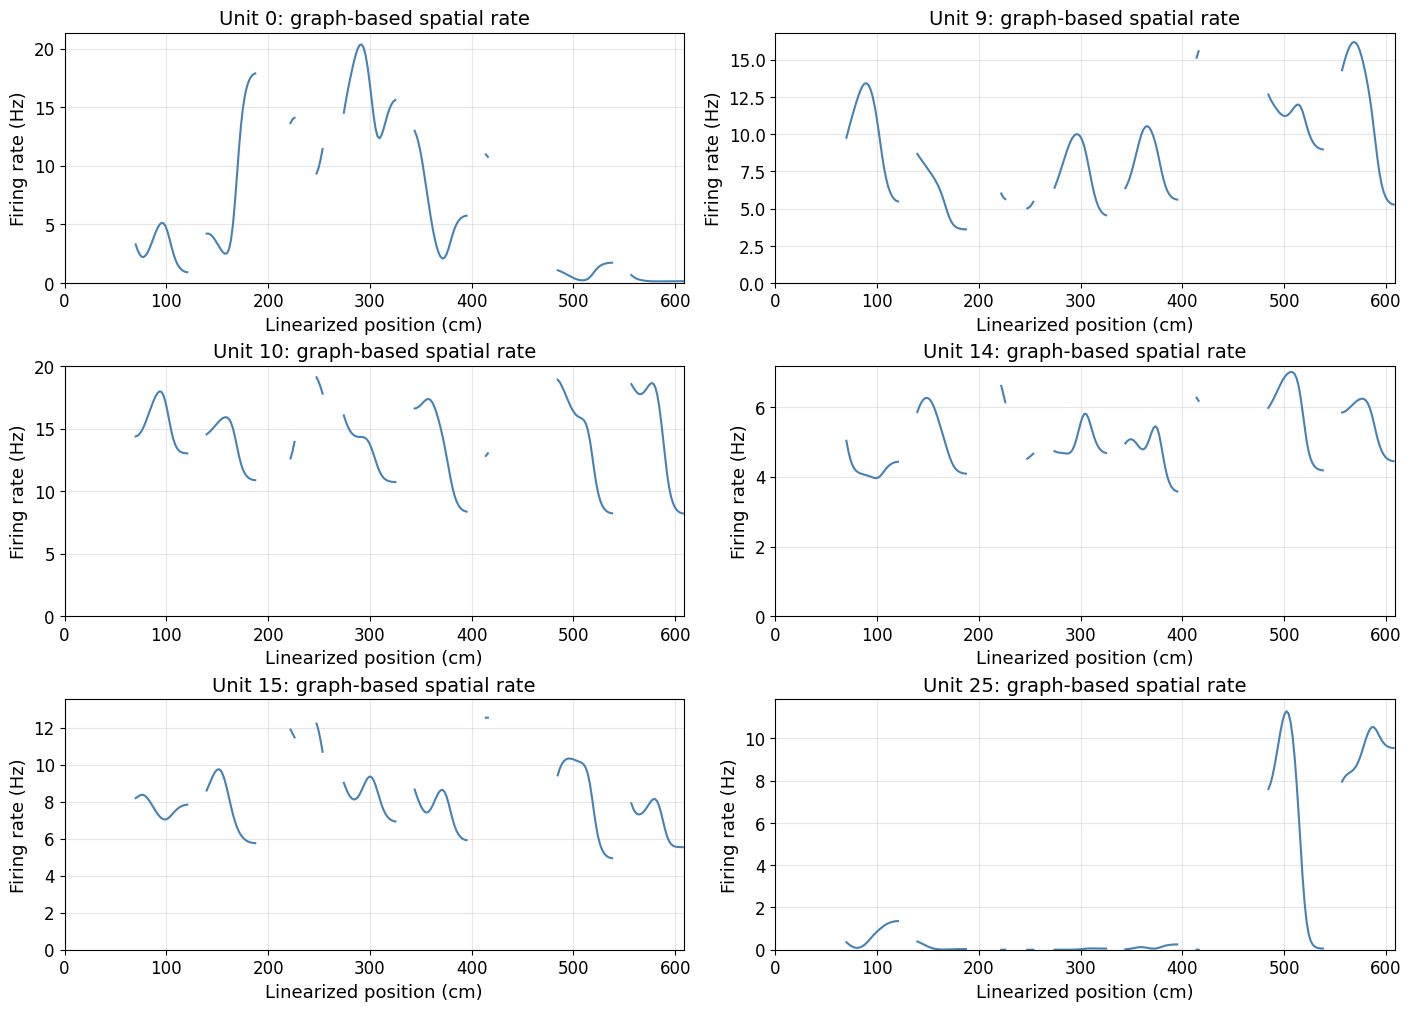

Graph support: 173 / 248 bins


In [14]:
track_rates = compute_spatial_rates(
    env_1d,
    [spike_times_all[unit_idx] for unit_idx in example_units],
    times_array,
    positions_array,
    unit_ids=example_units,
    bandwidth=bandwidth_cm,
    min_occupancy=min_occupancy_s,
    max_gap=max_gap,
)
linear_edges = env_1d.grid_edges[0]
linear_centers_full = (linear_edges[:-1] + linear_edges[1:]) / 2
linear_active = env_1d.active_mask.ravel()
np.testing.assert_allclose(linear_centers_full[linear_active], linear_bin_centers)
fig, axes = plt.subplots(3, 2, figsize=(14, 10), constrained_layout=True)
for ax, unit_idx in zip(axes.flat, example_units, strict=True):
    rate = track_rates.sel(unit_id=unit_idx)
    linear_field = np.full(linear_centers_full.shape, np.nan)
    linear_field[linear_active] = rate.firing_rate
    ax.plot(linear_centers_full, linear_field, color="steelblue")
    ax.set(
        xlabel="Linearized position (cm)",
        ylabel="Firing rate (Hz)",
        title=f"Unit {unit_idx}: graph-based spatial rate",
        ylim=(0, None),
        xlim=(linear_edges[0], linear_edges[-1]),
    )
    ax.grid(alpha=0.3)
plt.show()
print(f"Graph support: {track_rates.spatial_support.sum()} / {env_1d.n_bins} bins")

## Part 6b: Interactive Visualization with Napari

For interactive exploration, we can use napari to animate the animal's position
over a static rate map. The preview below covers the first 30 seconds, while
the map was estimated from the full epoch. It shows where the animal moved;
it does not estimate how a field changed over time.

Set `RUN_NAPARI = True` below to launch the optional desktop viewer.
This section requires napari (`pip install 'napari[all]'`).

In [15]:
# Prepare a short preview even when the desktop viewer is disabled.
preview_duration = 30.0
preview_indices = np.flatnonzero(times_array < times_array[0] + preview_duration)[::17]
positions_subsampled = positions_array[preview_indices]
times_subsampled = times_array[preview_indices]
best_unit = max(example_units, key=lambda u: spatial_metrics[u]["spatial_info"])
fields_animated = np.broadcast_to(
    place_fields[best_unit], (len(preview_indices), env_2d.n_bins)
)
position_overlay = PositionOverlay(
    positions=positions_subsampled,
    times=times_subsampled,
    color="cyan",
    size=15.0,
    trail_length=15,
)
overlays = [position_overlay]
if "head_orientation" in position_info.columns:
    overlays.append(
        HeadDirectionOverlay(
            headings=position_info["head_orientation"].to_numpy()[preview_indices],
            times=times_subsampled,
            color="yellow",
            length=10.0,
            width=2.0,
        )
    )
print(
    f"Unit {best_unit} preview: {times_subsampled[-1] - times_subsampled[0]:.2f} s, "
    f"{len(preview_indices)} frames"
)

Unit 0 preview: 29.99 s, 883 frames


In [16]:
# Opt in so running the whole notebook does not open a desktop window.
RUN_NAPARI = False
if RUN_NAPARI and importlib.util.find_spec("napari") is not None:
    env_2d.animate_fields(
        fields_animated,
        overlays=overlays,
        frame_times=times_subsampled,
        backend="napari",
        cmap="hot",
        title=f"Unit {best_unit} Place Field - Interactive",
    )
elif RUN_NAPARI:
    print("Install napari with: pip install 'napari[all]'")
else:
    print("Set RUN_NAPARI = True to open the optional desktop viewer.")

Set RUN_NAPARI = True to open the optional desktop viewer.


### Napari Features

The napari viewer provides:

- **Playback controls**: Play/pause, frame stepping, speed adjustment
- **Position overlay**: Cyan dot tracking the animal's location
- **Trail visualization**: Recent movement history shown as fading trail
- **Interactive exploration**: Zoom, pan, adjust contrast

For a complete video-export workflow, see
[16: field animation](16_field_animation.ipynb).

## Part 7: Segment Candidate Map Regions

`detect_place_fields()` segments above-threshold connected regions. We disable
its mean-rate exclusion heuristic here, because our aim is to describe maps,
and this export has no cell-type curation. We also disable recursive subfields
to keep the displayed regions disjoint.

A broad map fragmented by the occupancy mask can yield several candidate
regions. Neither their number nor their area establishes biological place
fields or a place-cell verdict. Check sensitivity to bin size, occupancy,
bandwidth and the relative threshold before interpreting them.

In [17]:
# Detect place fields for all example units
detected_fields_all = {}

for unit_idx in example_units:
    field = place_fields[unit_idx]

    # Detect place fields
    detected = detect_place_fields(
        env_2d,
        field,
        threshold=0.2,  # 20% of peak rate
        min_size=4,  # Minimum 4 bins
        max_mean_rate=np.inf,  # No cell-type exclusion for this descriptive exercise
        detect_subfields=False,
    )

    detected_fields_all[unit_idx] = detected

    print(f"Unit {unit_idx}: {len(detected)} candidate region(s)")

Unit 0: 9 candidate region(s)
Unit 9: 4 candidate region(s)
Unit 10: 3 candidate region(s)
Unit 14: 3 candidate region(s)
Unit 15: 3 candidate region(s)
Unit 25: 16 candidate region(s)


### Visualize Detected Fields for Each Cell

Each cell gets its own figure showing the place field with detected regions
(left) and spike locations (right):

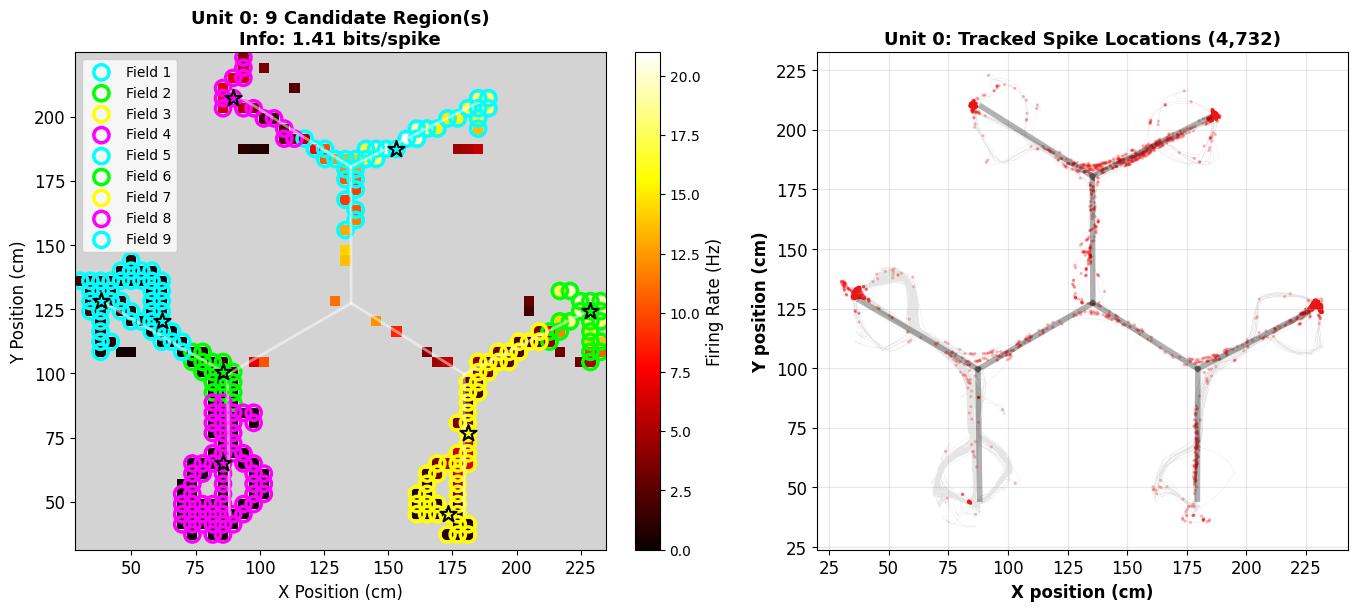

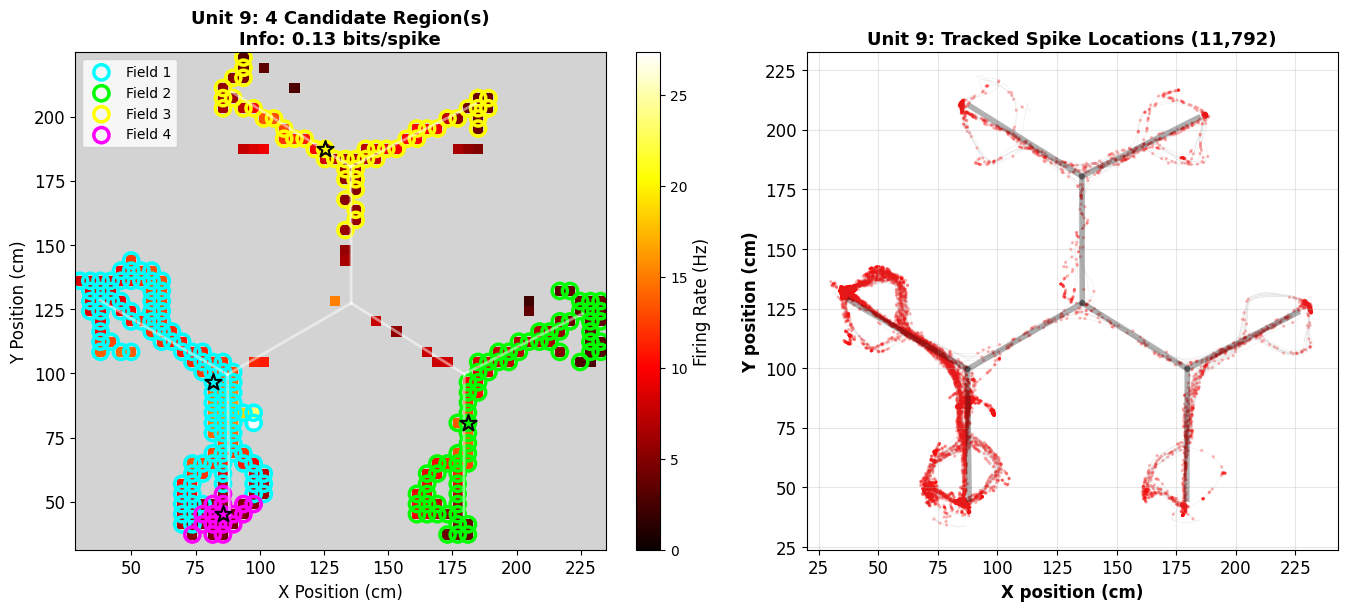

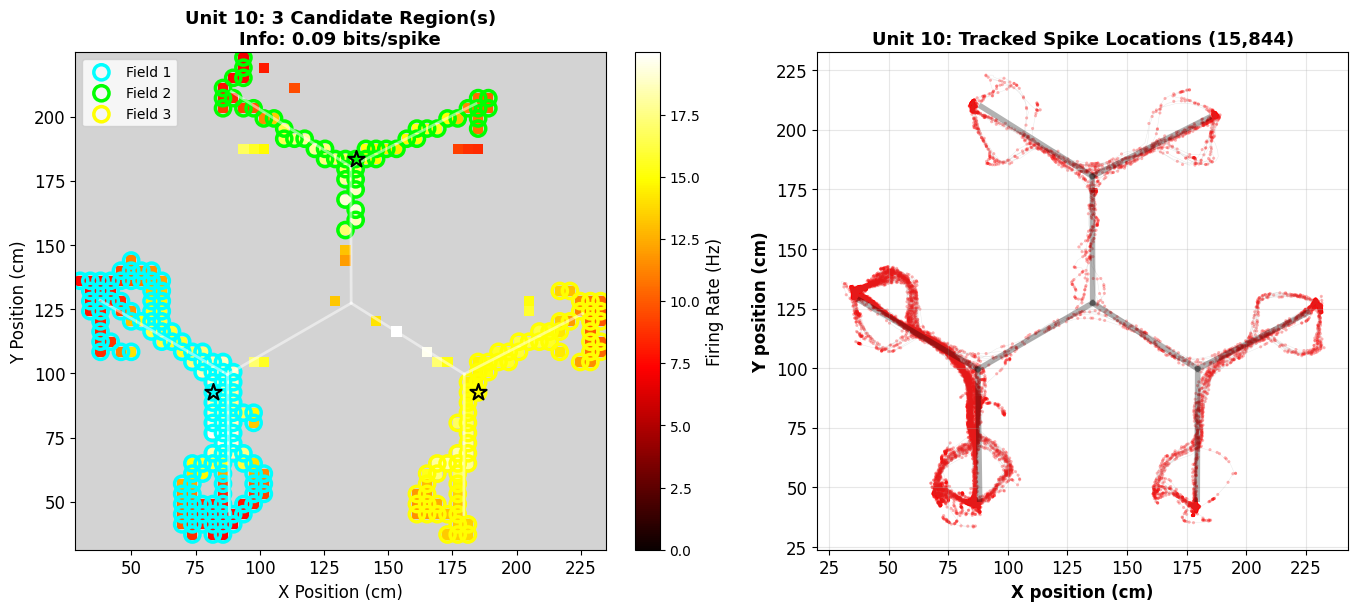

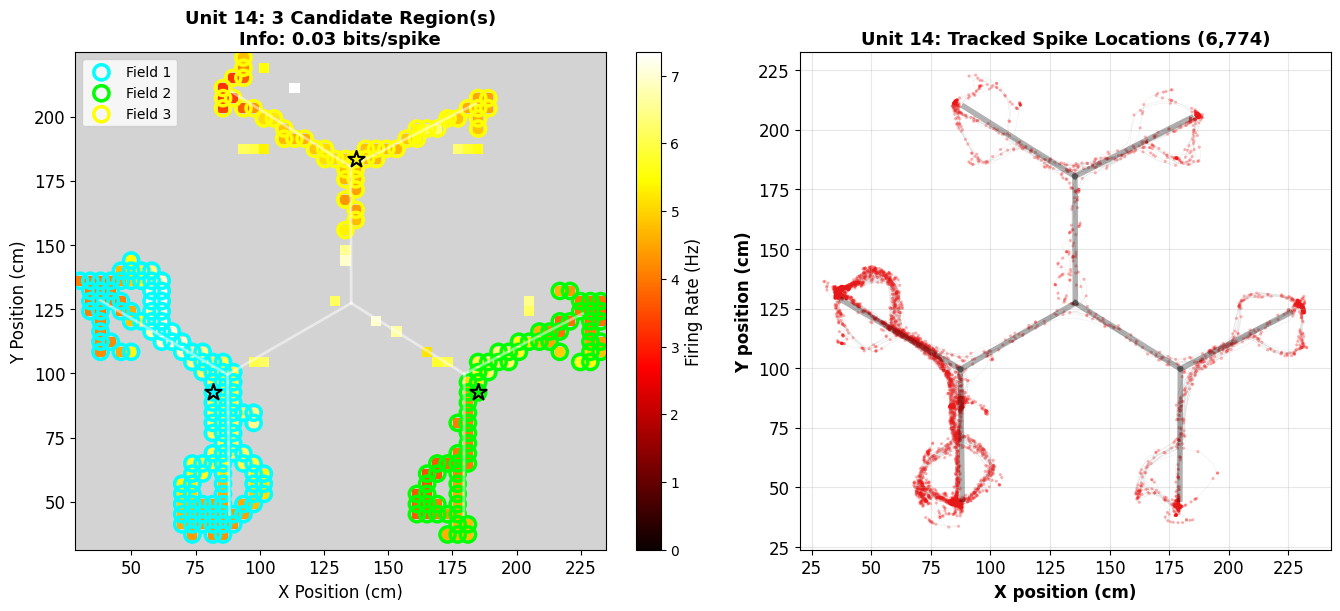

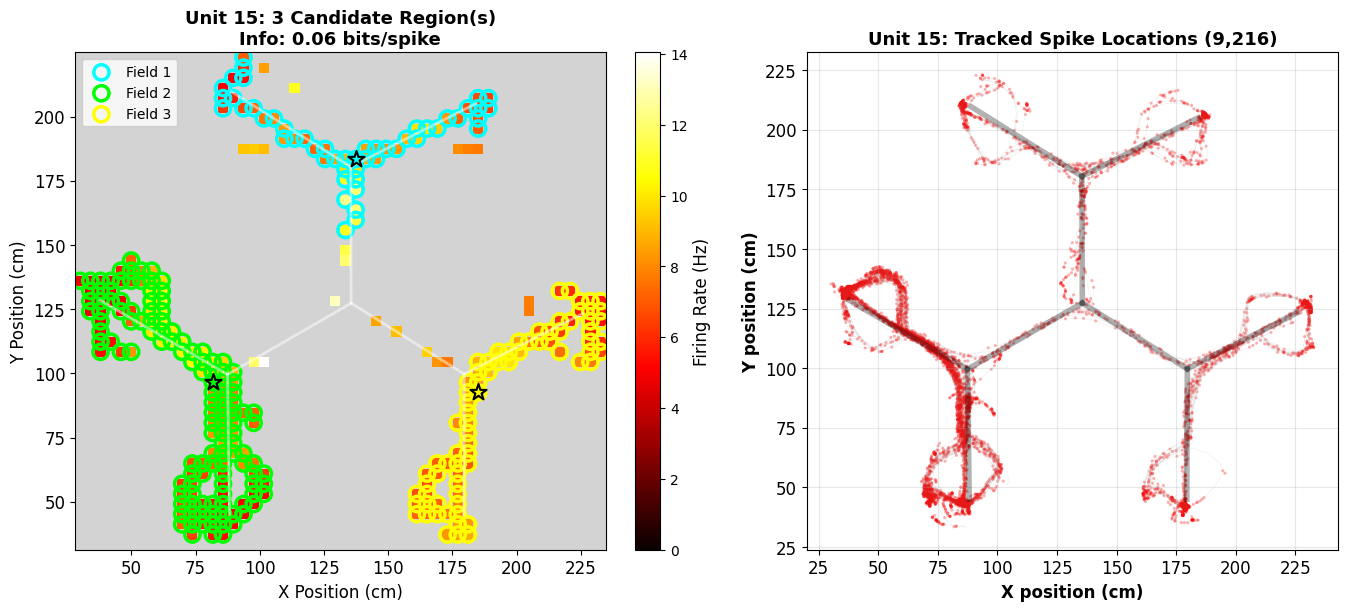

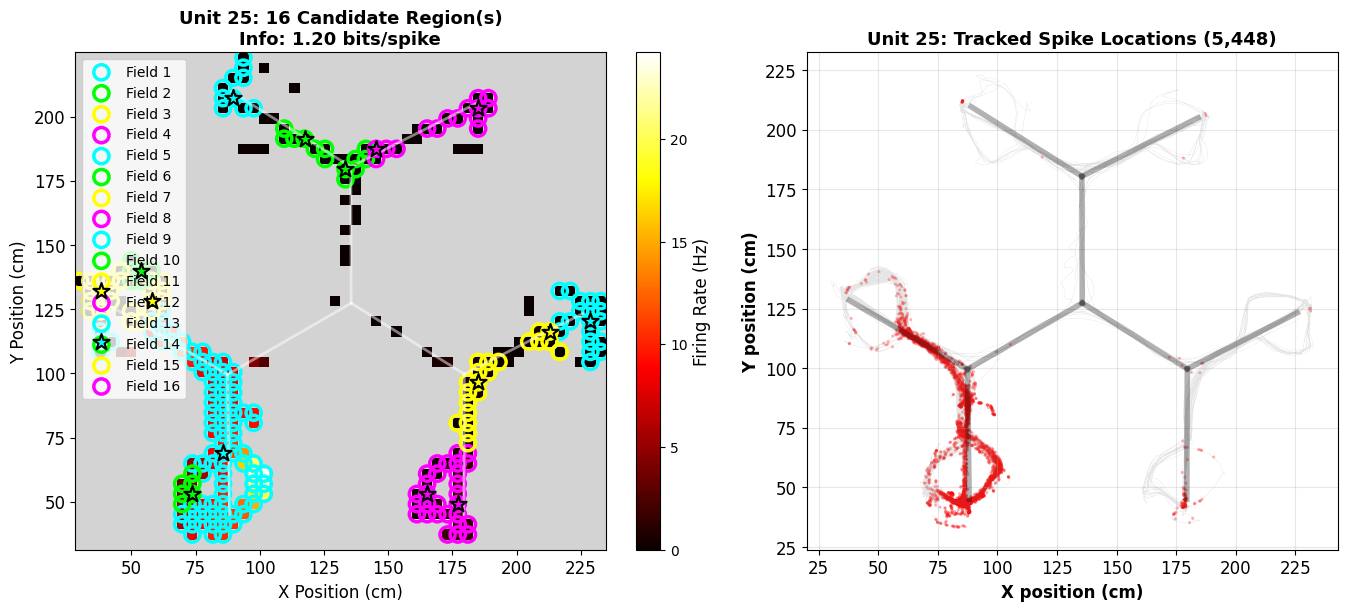

In [18]:
colors = ["cyan", "lime", "yellow", "magenta"]

for unit_idx in example_units:
    field = place_fields[unit_idx]
    detected_fields = detected_fields_all[unit_idx]
    m = spatial_metrics[unit_idx]

    fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

    # Left: Place field with detected regions highlighted
    ax = axes[0]
    env_2d.plot_field(
        field,
        ax=ax,
        cmap="hot",
        vmin=0,
        colorbar_label="Firing Rate (Hz)",
    )

    # Highlight detected field bins
    for i, field_bins in enumerate(detected_fields):
        ax.scatter(
            env_2d.bin_centers[field_bins, 0],
            env_2d.bin_centers[field_bins, 1],
            s=120,
            facecolors="none",
            edgecolors=colors[i % len(colors)],
            linewidths=2.5,
            label=f"Field {i + 1}",
        )

        # Mark the centroid under the sampled grid's connectivity.
        centroid = rate_map_centroid(env_2d, field, field_bins, method="geodesic")
        ax.scatter(
            centroid[0],
            centroid[1],
            s=150,
            c=colors[i % len(colors)],
            marker="*",
            edgecolors="black",
            linewidths=1.5,
            zorder=20,
        )

    # Add track overlay
    for u, v in track_graph.edges():
        pos_u = np.array(track_graph.nodes[u]["pos"])
        pos_v = np.array(track_graph.nodes[v]["pos"])
        ax.plot(
            [pos_u[0], pos_v[0]], [pos_u[1], pos_v[1]], "w-", linewidth=2, alpha=0.5
        )

    ax.set_title(
        f"Unit {unit_idx}: {len(detected_fields)} Candidate Region(s)\n"
        f"Info: {m['spatial_info']:.2f} bits/spike",
        fontsize=13,
        fontweight="bold",
    )
    if detected_fields:
        ax.legend(fontsize=10, loc="upper left")
    ax.set_aspect("equal")

    # Right: Spike locations
    ax = axes[1]

    # Plot trajectory
    ax.plot(
        positions_array[::50, 0],
        positions_array[::50, 1],
        "gray",
        alpha=0.2,
        linewidth=0.3,
    )

    # Plot spike locations
    spikes = spike_times_all[unit_idx]
    # Use the enclosing interval's start sample, as in occupancy allocation.
    # Exclude spikes outside tracking support or inside long tracking gaps.
    interval_indices = np.searchsorted(times_array, spikes, side="right") - 1
    tracked = (interval_indices >= 0) & (interval_indices < len(times_array) - 1)
    interval_indices = interval_indices[tracked]
    tracked_intervals = np.diff(times_array)[interval_indices] <= max_gap
    spike_positions = positions_array[interval_indices[tracked_intervals]]
    spike_positions = spike_positions[np.isfinite(spike_positions).all(axis=1)]
    ax.scatter(
        spike_positions[:, 0],
        spike_positions[:, 1],
        c="red",
        s=5,
        alpha=0.3,
        edgecolors="none",
    )

    # Add track overlay
    for u, v in track_graph.edges():
        pos_u = np.array(track_graph.nodes[u]["pos"])
        pos_v = np.array(track_graph.nodes[v]["pos"])
        ax.plot(
            [pos_u[0], pos_v[0]], [pos_u[1], pos_v[1]], "k-", linewidth=4, alpha=0.3
        )

    ax.set_xlabel("X position (cm)", fontsize=12, fontweight="bold")
    ax.set_ylabel("Y position (cm)", fontsize=12, fontweight="bold")
    ax.set_title(
        f"Unit {unit_idx}: Tracked Spike Locations ({len(spike_positions):,})",
        fontsize=13,
        fontweight="bold",
    )
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)

    plt.show()

### Candidate Region Summary

In [19]:
# Print summary of detected place fields
print("\n" + "=" * 70)
print("CANDIDATE REGION SUMMARY")
print("=" * 70)
print(
    f"{'Unit':<8} {'Regions':<10} {'Area (cm²)':<15} {'Peak Rate':<12} {'Sparsity':<10}"
)
print("-" * 70)

for unit_idx in example_units:
    detected_fields = detected_fields_all[unit_idx]
    field = place_fields[unit_idx]
    m = spatial_metrics[unit_idx]

    # Calculate total field area
    total_area = sum(field_size(env_2d, fb) for fb in detected_fields)

    print(
        f"{unit_idx:<8} {len(detected_fields):<10} {total_area:<15.1f} "
        f"{m['peak_rate']:<12.1f} {m['sparsity']:<10.3f}"
    )

print("-" * 70)


CANDIDATE REGION SUMMARY
Unit     Regions    Area (cm²)      Peak Rate    Sparsity  
----------------------------------------------------------------------
0        9          3925.3          21.0         0.253     
9        4          3988.1          27.3         0.845     
10       3          4003.8          20.0         0.884     
14       3          4003.8          7.3          0.961     
15       3          4003.8          14.0         0.924     
25       16         3642.7          24.2         0.393     
----------------------------------------------------------------------


## Part 8: Population Summary

Summarize the retained units descriptively. Low spike counts can yield unstable
maps and inflated information estimates, so a high information value alone
does not establish selectivity. These distributions describe our spike-count
selection and analysis settings; they do not estimate place-cell prevalence.

In [20]:
# Reuse the population maps computed above.
all_metrics = []

print("Computing spatial metrics for all active units...")
for unit_idx in active_units:
    spikes = spike_times_all[unit_idx]
    result = population_rates.sel(unit_id=unit_idx)
    firing_rate = result.firing_rate

    # Compute metrics
    info = result.spatial_information()
    sparse = result.sparsity()
    mean_rate = len(spikes) / duration
    peak_rate = np.nanmax(firing_rate)

    all_metrics.append(
        {
            "unit": unit_idx,
            "spike_count": spike_counts[unit_idx],
            "mean_rate": mean_rate,
            "peak_rate": peak_rate,
            "spatial_info": info,
            "sparsity": sparse,
        }
    )

print(f"Analyzed {len(all_metrics)} units")

Computing spatial metrics for all active units...
Analyzed 108 units


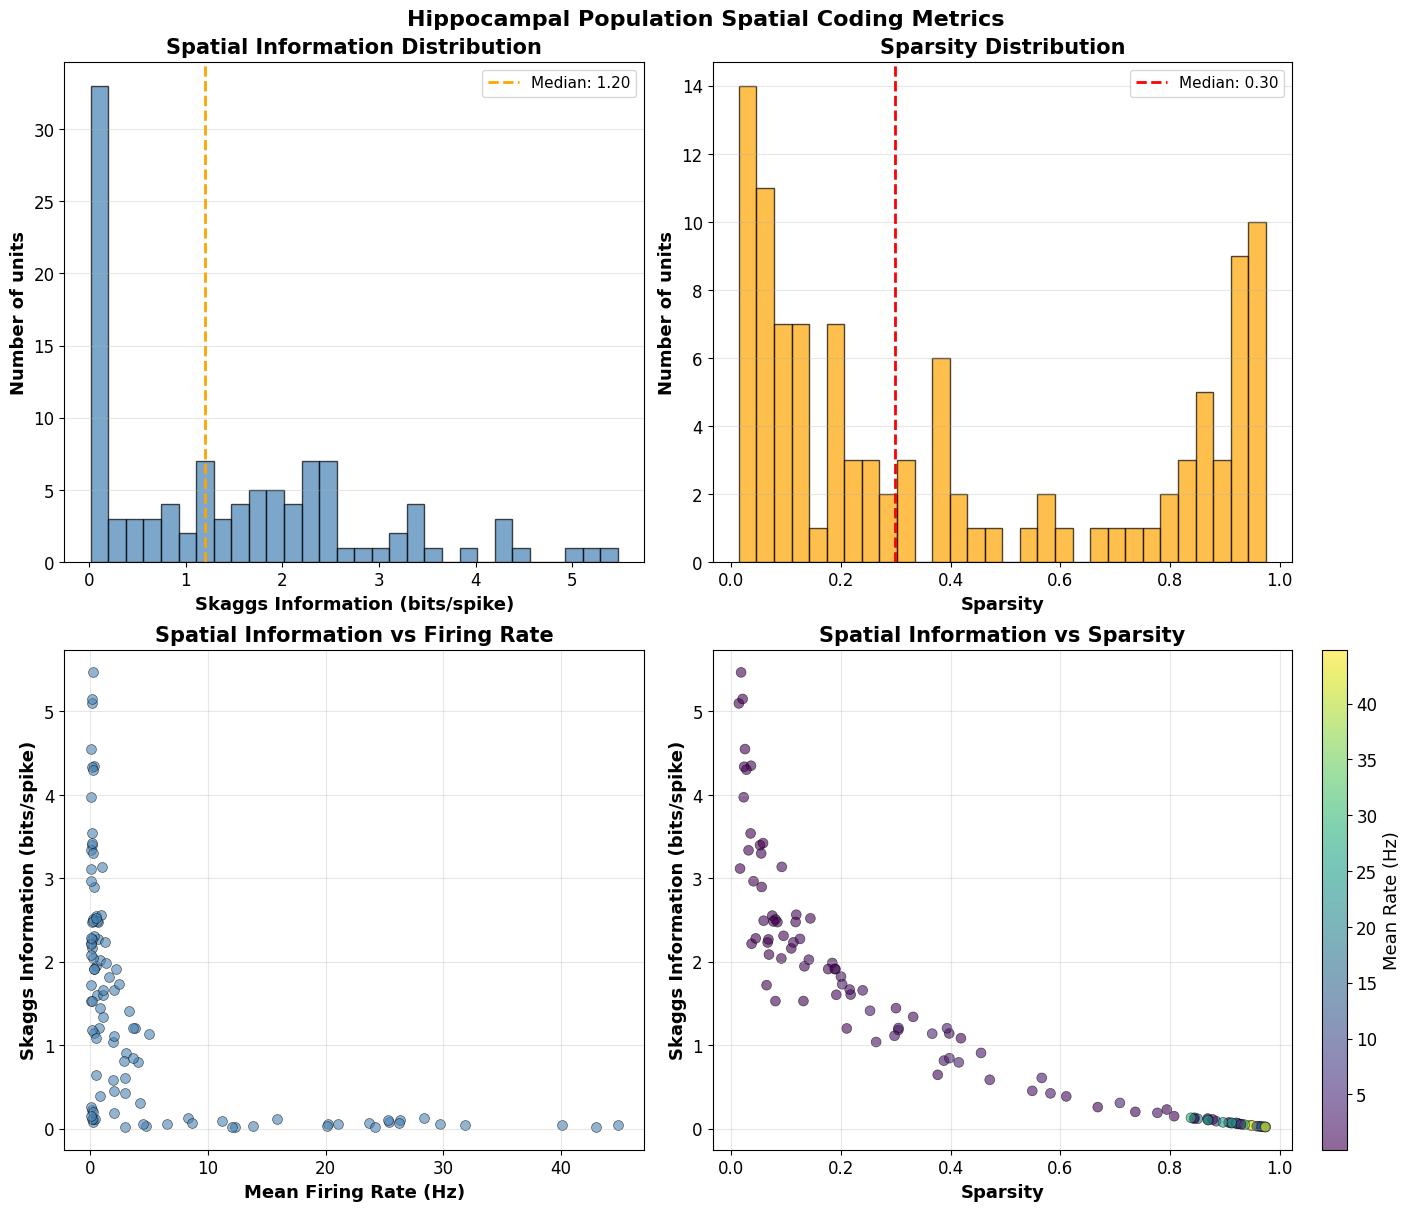


POPULATION SUMMARY

Total analyzed units: 108
These are descriptive metrics; cell-type inference requires a chosen test.

Spatial Information:
  Mean: 1.474 bits/spike
  Median: 1.203 bits/spike
  Max: 5.468 bits/spike

Sparsity:
  Mean: 0.420
  Median: 0.299


In [21]:
# Visualize population metrics
fig, axes = plt.subplots(2, 2, figsize=(14, 12), constrained_layout=True)

# Extract metrics as arrays
spatial_info_all = np.array([m["spatial_info"] for m in all_metrics])
sparsity_all = np.array([m["sparsity"] for m in all_metrics])
mean_rate_all = np.array([m["mean_rate"] for m in all_metrics])
peak_rate_all = np.array([m["peak_rate"] for m in all_metrics])

# Top-left: Spatial information distribution
ax = axes[0, 0]
ax.hist(spatial_info_all, bins=30, color="steelblue", edgecolor="black", alpha=0.7)
ax.axvline(
    np.median(spatial_info_all),
    color="orange",
    linestyle="--",
    linewidth=2,
    label=f"Median: {np.median(spatial_info_all):.2f}",
)
ax.set_xlabel("Skaggs Information (bits/spike)", fontsize=13, fontweight="bold")
ax.set_ylabel("Number of units", fontsize=13, fontweight="bold")
ax.set_title("Spatial Information Distribution", fontsize=15, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis="y")

# Top-right: Sparsity distribution
ax = axes[0, 1]
ax.hist(sparsity_all, bins=30, color="orange", edgecolor="black", alpha=0.7)
ax.axvline(
    np.median(sparsity_all),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Median: {np.median(sparsity_all):.2f}",
)
ax.set_xlabel("Sparsity", fontsize=13, fontweight="bold")
ax.set_ylabel("Number of units", fontsize=13, fontweight="bold")
ax.set_title("Sparsity Distribution", fontsize=15, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis="y")

# Bottom-left: Spatial info vs mean rate
ax = axes[1, 0]
ax.scatter(
    mean_rate_all,
    spatial_info_all,
    c="steelblue",
    s=50,
    alpha=0.6,
    edgecolors="black",
    linewidths=0.5,
)
ax.set_xlabel("Mean Firing Rate (Hz)", fontsize=13, fontweight="bold")
ax.set_ylabel("Skaggs Information (bits/spike)", fontsize=13, fontweight="bold")
ax.set_title("Spatial Information vs Firing Rate", fontsize=15, fontweight="bold")
ax.grid(True, alpha=0.3)

# Bottom-right: Spatial info vs sparsity
ax = axes[1, 1]
scatter = ax.scatter(
    sparsity_all,
    spatial_info_all,
    c=mean_rate_all,
    s=50,
    cmap="viridis",
    alpha=0.6,
    edgecolors="black",
    linewidths=0.5,
)
ax.set_xlabel("Sparsity", fontsize=13, fontweight="bold")
ax.set_ylabel("Skaggs Information (bits/spike)", fontsize=13, fontweight="bold")
ax.set_title("Spatial Information vs Sparsity", fontsize=15, fontweight="bold")
plt.colorbar(scatter, ax=ax, label="Mean Rate (Hz)")
ax.grid(True, alpha=0.3)

plt.suptitle(
    "Hippocampal Population Spatial Coding Metrics", fontsize=16, fontweight="bold"
)
plt.show()

# Summary statistics
print("\n" + "=" * 60)
print("POPULATION SUMMARY")
print("=" * 60)
print(f"\nTotal analyzed units: {len(all_metrics)}")
print("These are descriptive metrics; cell-type inference requires a chosen test.")
print("\nSpatial Information:")
print(f"  Mean: {np.mean(spatial_info_all):.3f} bits/spike")
print(f"  Median: {np.median(spatial_info_all):.3f} bits/spike")
print(f"  Max: {np.max(spatial_info_all):.3f} bits/spike")
print("\nSparsity:")
print(f"  Mean: {np.mean(sparsity_all):.3f}")
print(f"  Median: {np.median(sparsity_all):.3f}")

## Summary

In this notebook, we demonstrated neurospatial analysis with **real hippocampal
recording data** from a bandit task:

### Key Results

1. **Data Loading**: Successfully loaded neural data with 203 hippocampal units
   and 709,321 position samples

2. **Environment Creation**: Built a sampled 2D grid and a separate
   graph-based representation of the maze, and inspected occupancy/support

3. **Place Field Computation**: Used `compute_spatial_rates()` with diffusion KDE
   for boundary-aware smoothing and shared population computation

4. **Geometry Comparison**: Computed rate maps along the connected track graph
   and plotted them in linearized centimeters, with explicit display gaps

5. **Spatial Metrics**: Computed Skaggs information and sparsity for population
   analysis

6. **Candidate Regions**: Segmented descriptive above-threshold map regions;
   these do not establish cell type or statistical significance

7. **Optional Visualization**: Prepared a 30-second position/head-direction
   preview over a static full-epoch map; the napari viewer is opt-in

### Key Functions Used

- `Environment.from_graph()` - Create 1D linearized environment
- `Environment.from_samples()` - Create 2D spatial environment
- `compute_spatial_rates()` - Convert population spikes to labeled firing rate maps
- `env.animate_fields()` - Interactive napari visualization
- `PositionOverlay` - Animate animal position with trail
- `result.spatial_information()` - Measure spatial information (bits/spike)
- `result.sparsity()` - Measure how broadly activity is distributed
- `detect_place_fields()` - Automatic place field detection
- `field_size()`, `rate_map_centroid()` - Place field properties

### Next Steps

- Use linearized environment for trajectory-dependent analysis
- Segment trials and analyze behavior
- Compare place field stability across sessions
- Analyze population dynamics during decision-making

### References

- O'Keefe & Dostrovsky (1971): Discovery of place cells
- Skaggs et al. (1993): Spatial information metric
- Frank et al. (2000): Trajectory-dependent spatial coding